In [1]:
import pandas as pd
import numpy as np
import copepodTCR as cpp

import seaborn as sn
from matplotlib import pyplot as plt

# Figure 4:  CopepodTCR design identifies specificity of TCRs with unknown targets.

In [2]:
## Flow cytometry
Lu_fc = pd.read_csv('./data/FC_Lu1_Lu2_activation.tsv', sep = "\t")
cpp_scheme = pd.read_csv('./data/peptide-addresses_table.tsv', sep = "\t")
peptides = list(pd.read_csv('./data/peptides.tsv', sep = "\t", header = None)[0])

## HLA restriction data
exp_restr = pd.read_csv('./data/Lu1_Lu2_restriction.tsv', sep = "\t")

## pooling parameters
ep_length = 8
n_pools = 12
iters = 4

## Lu1

### C
Bayesian mixture model of observed pool activation signal (orange) for the read out obtained by flow cytometry. Blue lines show posterior draws from the fitted Bayesian mixture model, representing uncertainty in the inferred activation-signal distribution. The black line shows the mean of the posterior distribution.

Sequential sampling (2 chains in 1 job)
CompoundStep
>NUTS: [negative, offset_proportion, p, sigma_neg, sigm_pos, pool_dist, sigma_data]
>BinaryGibbsMetropolis: [assign]


Output()

Sampling 2 chains for 1_000 tune and 1_000 draw iterations (2_000 + 2_000 draws total) took 8 seconds.
/Users/kovaleva/miniforge3/envs/copepodTCR/lib/python3.10/site-packages/arviz/stats/diagnostics.py:596: RuntimeWarning: invalid value encountered in scalar divide
  (between_chain_variance / within_chain_variance + num_samples - 1) / (num_samples)
There were 295 divergences after tuning. Increase `target_accept` or reparameterize.
We recommend running at least 4 chains for robust computation of convergence diagnostics
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details
The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details
Sampling: [lik, negative_obs]


Output()

Posterior mean of p: 0.586
No drop-outs were detected
Cognate peptides: ['LPFFSNVTWFHAIHVSG', 'NVTWFHAIHVSGTNGTK']
Peptide candidates: ['LPFFSNVTWFHAIHVSG', 'NVTWFHAIHVSGTNGTK']


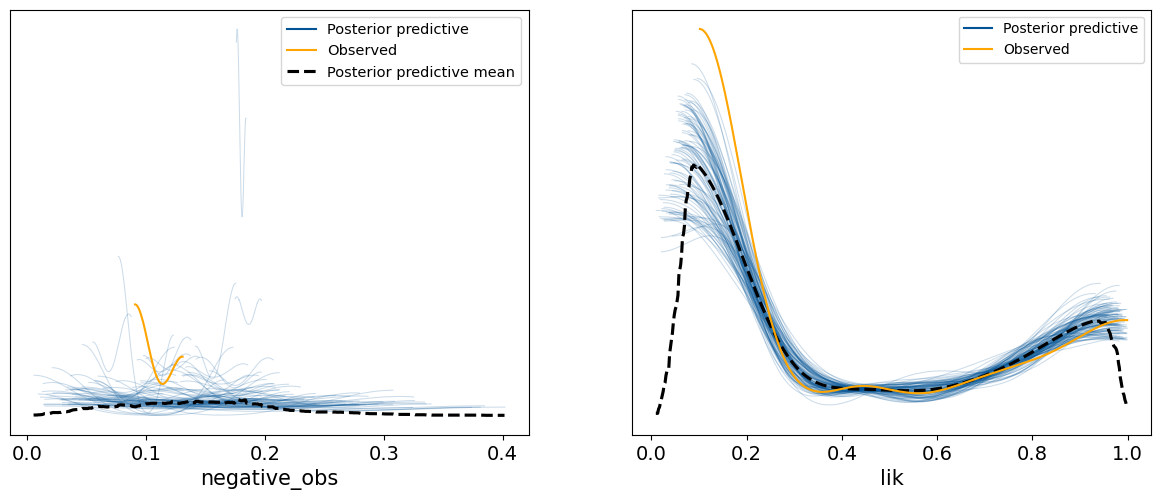

In [3]:
## preparing data for the model /100 because there are percentages
obs = np.array(Lu_fc['Lu1_fc(%)'][Lu_fc['type'] == 'pool'])/100
## pool indices
inds = np.array(Lu_fc['Pool'][Lu_fc['type'] == 'pool']).astype(int)
## negative control
neg_f1 = np.array(Lu_fc['Lu1_fc(%)'][Lu_fc['Pool'] == 'unstim'])/100

## calculating expected negative share
t, r = cpp.how_many_peptides(peptides, ep_length)
e = max(t, key=t.get)
neg_share = (n_pools - iters - e + 1)/n_pools

## fitting the model
model, fig, probs, n_c, pp, parameters = cpp.activation_model(obs, n_pools, inds, neg_f1, neg_share = neg_share)
## calculating peptide probabilities
peptide_probs = cpp.peptide_probabilities(cpp_scheme, probs)
## decision-tree algorithm
n_act_pools, message, most, possible = cpp.results_analysis(peptide_probs, probs, cpp_scheme)
print(message)
print(f'Cognate peptides: {most}')
print(f'Peptide candidates: {possible}')

### B
 Inferred
probability (from C) of each measurement coming from the distribution of activated pools (green) and from
a distribution of non-activated pools (gray).

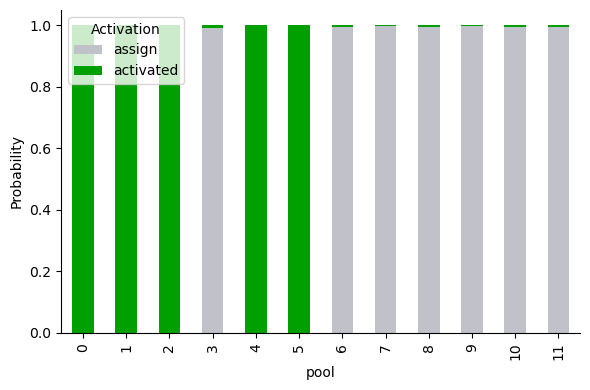

In [4]:
probs['activated'] = 1-probs['assign']
ax = probs.plot(kind="bar", stacked=True, figsize=(6, 4), color=["#C1C1CA", "#00A000"])
plt.legend(title="Activation")
plt.ylabel('Probability')
plt.tight_layout()
sn.despine()

### A
Flow cytometry read out as percentage of GFP-producing
(activated) cells in the T cell activation assay (y-axis) for each pool in the design (x-axis), with pools detected
as activated/non-activated in green and gray, respectively (determined from model fit in B.).

<Axes: title={'center': 'LPFFSNVTWFHAIHVSG or NVTWFHAIHVSGTNGTK'}, xlabel='Pools', ylabel='Log10 of activated T cell percentage'>

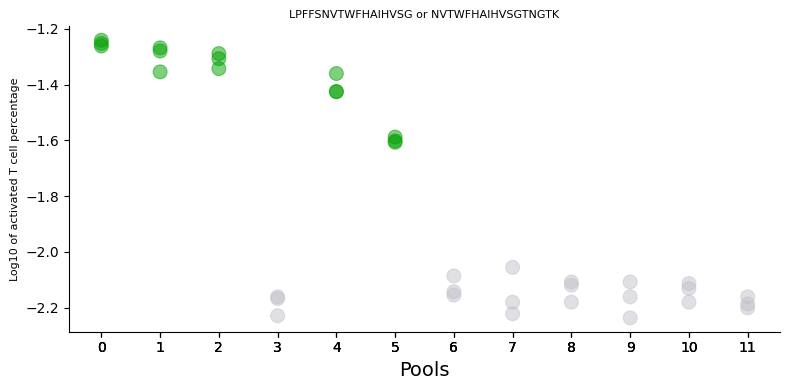

In [5]:
cpp.poolplot(probs, obs, inds, most)

### D
Per-peptide probabilities calculated from B. The size of the circle
shows the difference between the number of activated and non-activated pools to which a peptide was added.

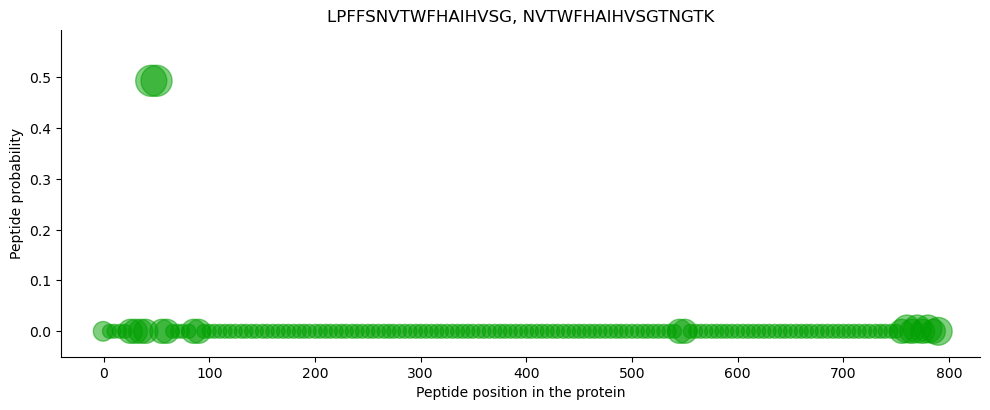

In [6]:
fig, axes = plt.subplots(1, 1, figsize=(10, 4))
cpp.bubbleplot(peptide_probs, ax = axes)
axes.set_title(', '.join(most))
sn.despine()

### E
Both cell lines strongly recognize both individual
overlapping peptides identified in the CPP experiment. Recognition does not occur in presence of HLA-DR
blocking antibody or if peptides are presented by DQB1:05:01-positive DRB1:16-negative donor

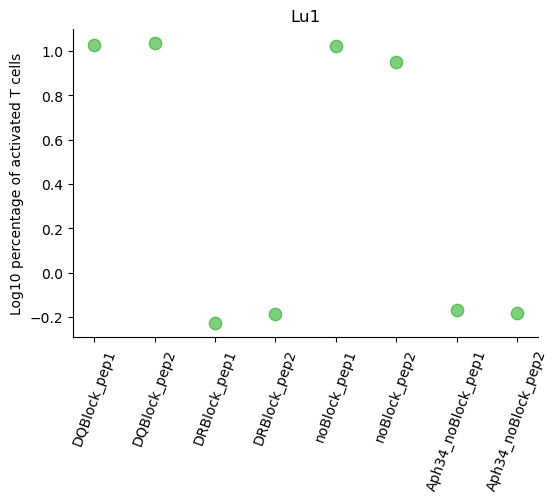

In [7]:
fig, axes = plt.subplots(figsize = (6, 4))
sn.scatterplot(x = exp_restr['type'], y = np.log10(exp_restr['Lu1_fc(%)']),
               s = 80, color = '#00A000', alpha = 0.5, edgecolor = '#00A000', linewidth = 1)
plt.xlabel('')
plt.ylabel('Log10 percentage of activated T cells')
plt.title('Lu1')
plt.xticks(rotation=70)
sn.despine()

## Lu2

### C
Bayesian mixture model of observed pool activation signal (orange) for the read out obtained by flow cytometry. Blue lines show posterior draws from the fitted Bayesian mixture model, representing uncertainty in the inferred activation-signal distribution. The black line shows the mean of the posterior distribution.

Sequential sampling (2 chains in 1 job)
CompoundStep
>NUTS: [negative, offset_proportion, p, sigma_neg, sigm_pos, pool_dist, sigma_data]
>BinaryGibbsMetropolis: [assign]


Output()

Sampling 2 chains for 1_000 tune and 1_000 draw iterations (2_000 + 2_000 draws total) took 9 seconds.
There were 296 divergences after tuning. Increase `target_accept` or reparameterize.
We recommend running at least 4 chains for robust computation of convergence diagnostics
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details
The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details
Sampling: [lik, negative_obs]


Output()

Posterior mean of p: 0.598
No drop-outs were detected
Cognate peptides: ['LPFFSNVTWFHAIHVSG', 'NVTWFHAIHVSGTNGTK']
Peptide candidates: ['LPFFSNVTWFHAIHVSG', 'NVTWFHAIHVSGTNGTK']


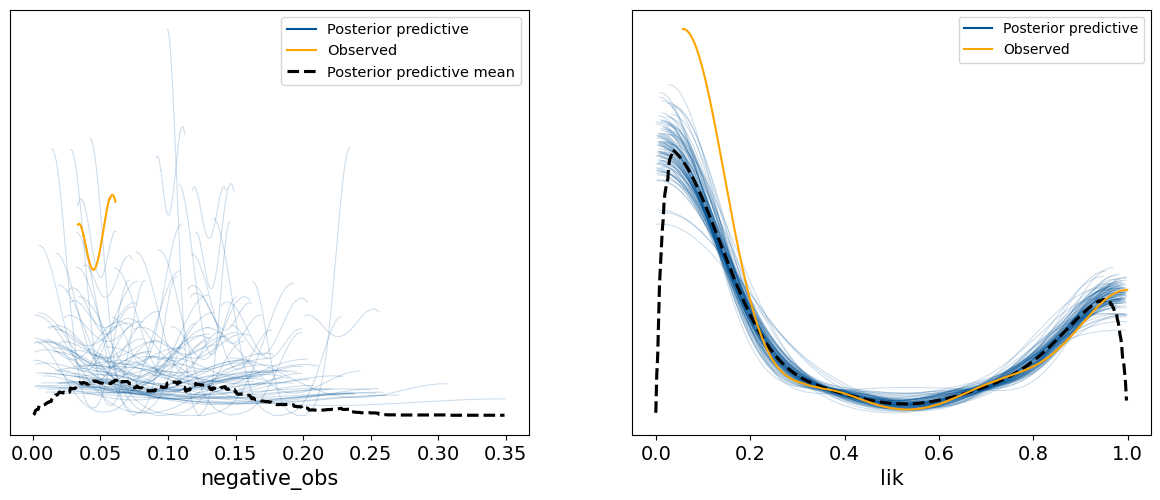

In [8]:
## preparing data for the model /100 because there are percentages
obs = np.array(Lu_fc['Lu2_fc(%)'][Lu_fc['type'] == 'pool'])/100
## pool indices
inds = np.array(Lu_fc['Pool'][Lu_fc['type'] == 'pool']).astype(int)
## negative control
neg_f1 = np.array(Lu_fc['Lu2_fc(%)'][Lu_fc['Pool'] == 'unstim'])/100

## calculating expected negative share
t, r = cpp.how_many_peptides(peptides, ep_length)
e = max(t, key=t.get)
neg_share = (n_pools - iters - e + 1)/n_pools

## fitting the model
model, fig, probs, n_c, pp, parameters = cpp.activation_model(obs, n_pools, inds, neg_f1, neg_share = neg_share)
## calculating peptide probabilities
peptide_probs = cpp.peptide_probabilities(cpp_scheme, probs)
## decision-tree algorithm
n_act_pools, message, most, possible = cpp.results_analysis(peptide_probs, probs, cpp_scheme)
print(message)
print(f'Cognate peptides: {most}')
print(f'Peptide candidates: {possible}')

### B
 Inferred
probability (from C) of each measurement coming from the distribution of activated pools (green) and from
a distribution of non-activated pools (gray).

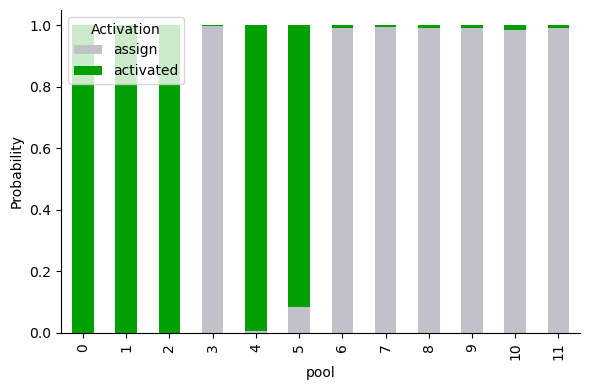

In [9]:
probs['activated'] = 1-probs['assign']
ax = probs.plot(kind="bar", stacked=True, figsize=(6, 4), color=["#C1C1CA", "#00A000"])
plt.legend(title="Activation")
plt.ylabel('Probability')
plt.tight_layout()
sn.despine()

### A
Flow cytometry read out as percentage of GFP-producing
(activated) cells in the T cell activation assay (y-axis) for each pool in the design (x-axis), with pools detected
as activated/non-activated in green and gray, respectively (determined from model fit in B.).

<Axes: title={'center': 'LPFFSNVTWFHAIHVSG or NVTWFHAIHVSGTNGTK'}, xlabel='Pools', ylabel='Log10 of activated T cell percentage'>

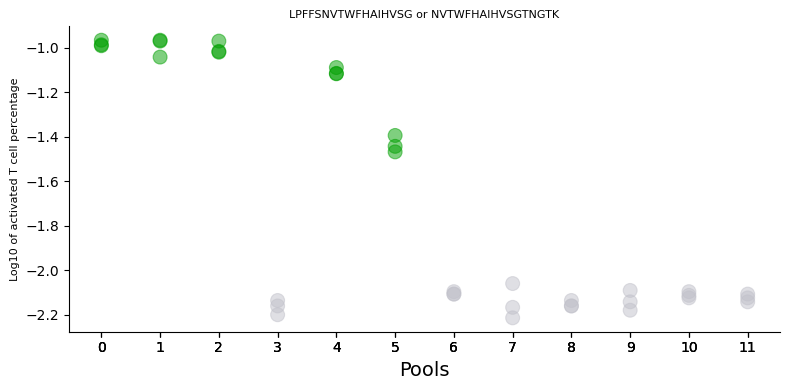

In [10]:
cpp.poolplot(probs, obs, inds, most)

### D
Per-peptide probabilities calculated from B. The size of the circle
shows the difference between the number of activated and non-activated pools to which a peptide was added.

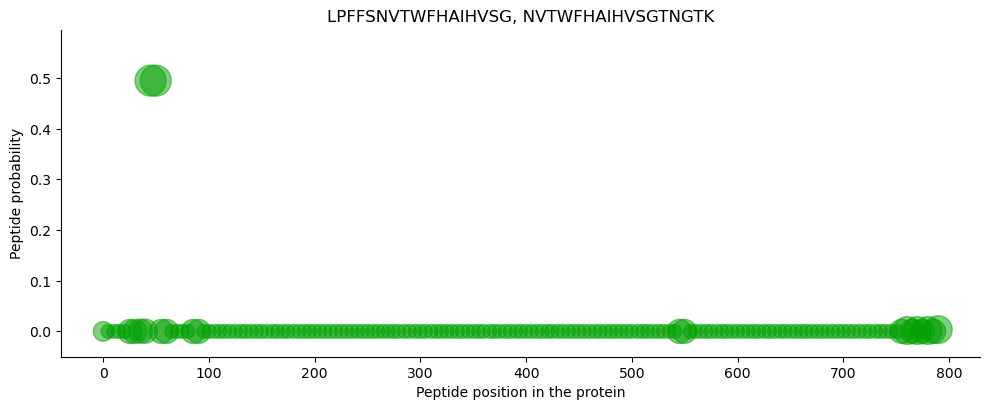

In [11]:
fig, axes = plt.subplots(1, 1, figsize=(10, 4))
cpp.bubbleplot(peptide_probs, ax = axes)
axes.set_title(', '.join(most))
sn.despine()

### E
Both cell lines strongly recognize both individual
overlapping peptides identified in the CPP experiment. Recognition does not occur in presence of HLA-DR
blocking antibody or if peptides are presented by DQB1:05:01-positive DRB1:16-negative donor

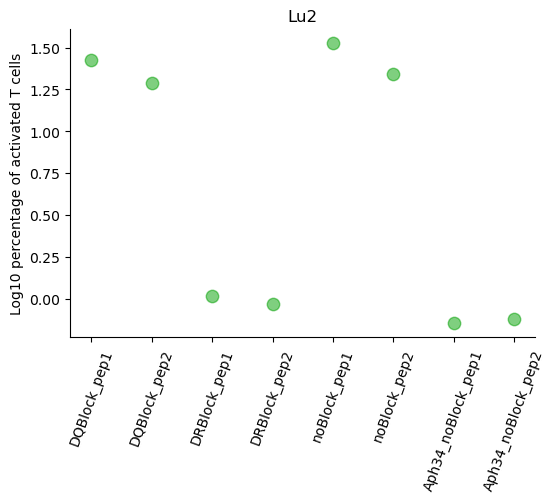

In [12]:
fig, axes = plt.subplots(figsize = (6, 4))
sn.scatterplot(x = exp_restr['type'], y = np.log10(exp_restr['Lu2_fc(%)']),
               s = 80, color = '#00A000', alpha = 0.5, edgecolor = '#00A000', linewidth = 1)
plt.xlabel('')
plt.ylabel('Log10 percentage of activated T cells')
plt.title('Lu2')
plt.xticks(rotation=70)
sn.despine()